# 4. Core Primitives — State, Nodes, Edges

Video 3 got a one-node graph working end to end, and gave Priya's Applicant Screener its first node: parse a resume into structured fields. This notebook slows down and treats **state**, **nodes**, and **edges** as first-class concepts worth understanding deeply, rather than "the thing that made Video 3 work."

**Sections**
1. Recap: the utility + helper from Video 3
2. State in depth — the node contract and default merge behavior
3. Nodes are just Python — arbitrary code, fixed signature
4. Edges so far — `add_edge`, and a heads-up about conditional edges
5. Growing the Applicant Screener Pipeline into three linear nodes
6. State schema design judgment

## 1. Recap: the utility + helper from Video 3

Same `llm_utils.py` as last time — one `call_llm(provider, messages, system=None)` function, defaulting to Claude. If you're running this notebook fresh (not right after Video 3's), the cell below recreates it.

In [ ]:
%pip install -r requirements.txt

In [1]:
import os, getpass
from dotenv import load_dotenv

load_dotenv()

for env_var in ["ANTHROPIC_API_KEY", "OPENAI_API_KEY", "GOOGLE_API_KEY"]:
    if not os.environ.get(env_var):
        os.environ[env_var] = getpass.getpass(f"{env_var}: ")

In [2]:
from typing import TypedDict
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

from llm_utils import call_llm


def show_graph(graph):
    """Render a compiled graph. Falls back to Mermaid text if the PNG renderer is unavailable."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())

## 2. State in depth — the node contract and default merge behavior

A **state schema** is just a `TypedDict` (or dataclass) describing the shape of the data flowing through the graph. What matters is the **contract** every node honors:

> A node receives the **entire current state**, and returns a **partial update** — only the fields it's changing, not a full replacement.

LangGraph merges that partial update back into the whole state for you. With no special configuration, the default merge behavior is **last-write-wins per field**: if a node's return dict includes a key, that key's value is overwritten with the new one.

That raises an obvious question: *what if two different nodes need to touch the same field — say, both want to add something to a running list, not replace it?* Hold that thought — default overwrite behavior can't do that, and that's exactly the problem **reducers** solve in Video 6. For today, just notice the question exists.

In [3]:
class DemoState(TypedDict):
    counter: int
    note: str


def set_counter_to_1(state: DemoState) -> dict:
    # Only returns "counter" -> "note" is left untouched in the merged state.
    return {"counter": 1}


def set_counter_to_2(state: DemoState) -> dict:
    # Receives the FULL state (counter == 1 here), but again only returns a partial update.
    print("set_counter_to_2 sees the full state:", state)
    return {"counter": 2, "note": "overwritten, not merged"}


demo_builder = StateGraph(DemoState)
demo_builder.add_node("set_counter_to_1", set_counter_to_1)
demo_builder.add_node("set_counter_to_2", set_counter_to_2)
demo_builder.add_edge(START, "set_counter_to_1")
demo_builder.add_edge("set_counter_to_1", "set_counter_to_2")
demo_builder.add_edge("set_counter_to_2", END)

demo_graph = demo_builder.compile()
demo_graph.invoke({"counter": 0, "note": "initial"})

set_counter_to_2 sees the full state: {'counter': 1, 'note': 'initial'}


{'counter': 2, 'note': 'overwritten, not merged'}

Notice: `counter` ends at `2` (last write wins), and `note` also ends at whatever `set_counter_to_2` last set — the default behavior always overwrites a field the moment any node returns a value for it. There's no built-in "combine the old and new value" behavior yet. Keep that in mind; we'll revisit it directly in Video 6 once we have a real accumulating field (a running list of notes) in the Applicant Screener.

## 3. Nodes are just Python — arbitrary code, fixed signature

A node's *signature* is fixed (state in, partial-update dict out), but its *body* can be anything: an LLM call, pure computation, a database lookup, file I/O — the graph doesn't care what's inside a node, only its input/output contract. To make that concrete, here's a node with **no LLM call at all**, next to one that has one — both are equally valid nodes.

In [4]:
class MixedState(TypedDict):
    resume_text: str
    word_count: int
    tone_comment: str


def count_words(state: MixedState) -> dict:
    # Pure Python. No LLM, no I/O. Still a completely normal node.
    return {"word_count": len(state["resume_text"].split())}


def comment_on_tone(state: MixedState) -> dict:
    # An LLM call. Also a completely normal node - same signature as count_words.
    result = call_llm(
        "claude",
        messages=[{"role": "user", "content": f"In five words or fewer, describe the tone of this resume excerpt:\n{state['resume_text']}"}],
    )
    return {"tone_comment": result.content}


mixed_builder = StateGraph(MixedState)
mixed_builder.add_node("count_words", count_words)
mixed_builder.add_node("comment_on_tone", comment_on_tone)
mixed_builder.add_edge(START, "count_words")
mixed_builder.add_edge("count_words", "comment_on_tone")
mixed_builder.add_edge("comment_on_tone", END)

mixed_graph = mixed_builder.compile()
mixed_graph.invoke({"resume_text": "Led a 4-person backend team, shipped a payments API used by 2M users."})

{'resume_text': 'Led a 4-person backend team, shipped a payments API used by 2M users.',
 'word_count': 13,
 'tone_comment': 'Confident, results-driven, and direct'}

## 4. Edges so far — `add_edge`, and a heads-up about conditional edges

Every edge we've used so far is an **unconditional edge** via `add_edge(from_node, to_node)`: whatever happens in `from_node`, the graph always proceeds to `to_node` next. That's the entire story for a purely linear pipeline like the one we're about to build.

It won't stay the only kind of edge — soon we'll need the path itself to depend on runtime data (e.g. "route to `reject` if the score is low, `interview` if it's mid, `strong_match` if it's high"). That's a **conditional edge**, and it's coming in a later video. For now, just know the word exists so it doesn't feel like a gap.

## 5. Priya's next complaint: "Fields don't tell me whom to call"

Video 3's `parse_resume` turned each resume into name, years, skills and leadership. Priya now wants a **verdict**: a score against her own rubric (experience up to 40 points, skills up to 40, leadership up to 20), plus a short note she can pass to the hiring manager.

We add two more nodes, wired **linearly** with `add_edge` (no branching yet, that's still ahead):

```
parse_resume -> score_against_rubric -> generate_summary
```

- **Input:** one raw resume string.
- **Output:** the four parsed fields, plus a numeric `score`, a one-sentence `score_rationale`, and a two-sentence `summary`.

Watch the state schema **grow field by field** as each node is added. That's normal, deliberate design, not a sign something was planned wrong up front. We'll run all three candidates (Hermione, Harry and Ron) through the same pipeline.

In [5]:
# The three candidates we follow through every notebook in this story.
RESUMES = {
    "Hermione": """
Hermione Granger
7 years of experience as a senior backend software engineer.
Skills: Python, distributed systems, SQL, PostgreSQL, Kubernetes, API design.
Led a 6-person platform team at a fintech company, mentoring junior engineers.
""",
    "Harry": """
Harry Potter
4 years of experience as a software developer.
Skills: Python, SQL, REST APIs.
Informally mentored two interns. No distributed systems or Kubernetes experience.
""",
    "Ron": """
Ron Weasley
8 months of experience as a junior web developer.
Skills: HTML, CSS, basic JavaScript.
No team or leadership experience.
""",
}

In [6]:
# Step 1: the state schema as it stood at the end of Video 3.
class ScreenerStateV1(TypedDict):
    resume_text: str
    candidate_name: str
    years_experience: str
    skills: str
    leadership: str


# Step 2: today's additions - a numeric score plus the rationale behind it, and a final summary.
class ScreenerState(ScreenerStateV1):
    score: int
    score_rationale: str
    summary: str

In [7]:
PARSE_SYSTEM_PROMPT = (
    "You extract structured fields from a resume. Reply with exactly four lines, "
    "no extra commentary:\n"
    "Name: <candidate name>\n"
    "Years: <years of experience as a number>\n"
    "Skills: <comma-separated skills>\n"
    "Leadership: <one short phrase on leadership or mentoring experience, or none>"
)


def parse_resume(state: ScreenerState) -> dict:
    result = call_llm(
        "claude",
        messages=[{"role": "user", "content": state["resume_text"]}],
        system=PARSE_SYSTEM_PROMPT,
    )

    fields = {"candidate_name": "", "years_experience": "", "skills": "", "leadership": ""}
    for line in result.content.strip().splitlines():
        if line.startswith("Name:"):
            fields["candidate_name"] = line.removeprefix("Name:").strip()
        elif line.startswith("Years:"):
            fields["years_experience"] = line.removeprefix("Years:").strip()
        elif line.startswith("Skills:"):
            fields["skills"] = line.removeprefix("Skills:").strip()
        elif line.startswith("Leadership:"):
            fields["leadership"] = line.removeprefix("Leadership:").strip()
    return fields

In [8]:
RUBRIC = (
    "Score the candidate from 0-100 against this fixed rubric:\n"
    "- 5+ years experience: up to 40 points\n"
    "- Skills overlap with [Python, distributed systems, Kubernetes, SQL]: up to 40 points\n"
    "- Leadership experience mentioned: up to 20 points\n"
    "Reply with exactly two lines, no extra commentary:\n"
    "Score: <integer 0-100>\n"
    "Rationale: <one sentence>"
)


def score_against_rubric(state: ScreenerState) -> dict:
    print("state", state)
    candidate_summary = (
        f"Name: {state['candidate_name']}\n"
        f"Years of experience: {state['years_experience']}\n"
        f"Skills: {state['skills']}\n"
        f"Leadership: {state['leadership']}"
    )
    result = call_llm(
        "claude",
        messages=[{"role": "user", "content": candidate_summary}],
        system=RUBRIC,
    )

    score, rationale = 0, ""
    for line in result.content.strip().splitlines():
        if line.startswith("Score:"):
            score = int("".join(ch for ch in line if ch.isdigit()) or 0)
        elif line.startswith("Rationale:"):
            rationale = line.removeprefix("Rationale:").strip()
    return {"score": score, "score_rationale": rationale}

In [9]:
def generate_summary(state: ScreenerState) -> dict:
    prompt = (
        f"Candidate: {state['candidate_name']}\n"
        f"Score: {state['score']}/100 ({state['score_rationale']})\n\n"
        "Write a two-sentence plain-text summary of this candidate for a hiring manager."
    )
    result = call_llm("claude", messages=[{"role": "user", "content": prompt}])
    return {"summary": result.content}

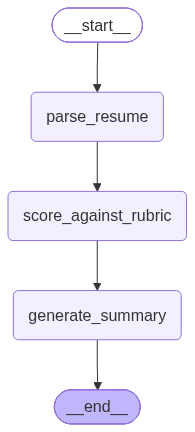

In [10]:
screener_builder = StateGraph(ScreenerState)
screener_builder.add_node("parse_resume", parse_resume)
screener_builder.add_node("score_against_rubric", score_against_rubric)
screener_builder.add_node("generate_summary", generate_summary)

screener_builder.add_edge(START, "parse_resume")
screener_builder.add_edge("parse_resume", "score_against_rubric")
screener_builder.add_edge("score_against_rubric", "generate_summary")
screener_builder.add_edge("generate_summary", END)

screener_graph = screener_builder.compile()
show_graph(screener_graph)

In [11]:
for name, resume in RESUMES.items():
    print(f"=== {name} ===")
    result = screener_graph.invoke({"resume_text": resume})
    for key, value in result.items():
        if key != "resume_text":
            print(f"{key}: {value}")
    print()

=== Hermione ===
state {'resume_text': '\nHermione Granger\n7 years of experience as a senior backend software engineer.\nSkills: Python, distributed systems, SQL, PostgreSQL, Kubernetes, API design.\nLed a 6-person platform team at a fintech company, mentoring junior engineers.\n', 'candidate_name': 'Hermione Granger', 'years_experience': '7', 'skills': 'Python, distributed systems, SQL, PostgreSQL, Kubernetes, API design', 'leadership': 'Led a 6-person platform team, mentoring junior engineers'}
candidate_name: Hermione Granger
years_experience: 7
skills: Python, distributed systems, SQL, PostgreSQL, Kubernetes, API design
leadership: Led a 6-person platform team, mentoring junior engineers
score: 100
score_rationale: Candidate has 7 years of experience, matches all four required skills, and demonstrates clear leadership by leading and mentoring a 6-person team.
summary: Hermione Granger is a highly qualified candidate with 7 years of experience, achieving a perfect score of 100/100 

Even though this graph is purely linear (no branching, no loops), it's already a legitimate, useful pipeline. Not every graph needs to branch to earn being a graph.

It also gives Priya what she asked for: the *same* pipeline produces a high score for Hermione, a middling one for Harry and a low one for Ron. But it still treats all three the same way, with the same kind of summary and no decision about what happens next. That's what Video 7 fixes.

## 6. State schema design judgment

A few practical tradeoffs worth being deliberate about as a schema grows:

- **Minimal vs. debuggable.** `ScreenerState` could have skipped `score_rationale` and `years_experience`/`skills` as separate fields — `generate_summary` only strictly needs `candidate_name` and `score`. But keeping the intermediate fields around means you can inspect *why* a score came out the way it did, without re-running anything. That's usually worth the extra fields, especially while a pipeline is still being tuned.
- **Required vs. optional.** Every field in a `TypedDict` is implicitly required unless you mark it `NotRequired[...]`. If a node might legitimately not produce a field (e.g. a future "flag for manual review" field that's only set sometimes), say so explicitly rather than relying on nodes always filling in a placeholder.
- **One field, one purpose.** Resist cramming multiple concerns into a single string field (e.g. `"score: 82, rationale: ..."` as one blob) just to avoid adding a field — it saves a line of schema now and costs you string-parsing everywhere downstream.

None of this is fixed once written — a schema growing over several videos, as ours just did, is the normal and expected shape of building a graph iteratively.

**Next video** covers the Graph API vs. the Functional API — the same three-node pipeline we just built, reimplemented with `@entrypoint`/`@task` to see the same engine through a different syntax.